# skf-ds-home-assignment

# Industrial Motor Temperature Anomaly Detection

## Problem Definition

- **Goal:** Assign an `alarm` or `no_alarm` label to every processed temperature measurement.

- **Input:** Two years of timestamped motor-temperature readings stored in daily Parquet files.

- **Available labels:** The dataset contains no confirmed anomaly labels, and the motor is assumed to operate normally most of the time.

- **Target behavior:** A consistent, gradual increase in temperature.

- **Prediction constraint:** Each new row should be assigned as alarm or not 

- **Non-target behavior:** Isolated temperature spikes, sensor glitches, or short-lived deviations should not by themselves trigger a gradual-trend alarm. They may be reported separately as data-quality warnings or signals\features.

- **Evaluation constraint:** Because confirmed anomaly labels are unavailable, the analysis should reveal the saught for pattern to detect and build features for either simple statistics thresholds or unsupervised techniques



In [1]:
import glob

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.linear_model import HuberRegressor


# Part 1: Exploratory Data Analysis (EDA)

## 1. Load and inspect the data

Load all daily partitions into one table, then verify the basic schema and data quality before interpreting patterns.


In [2]:
files = sorted(glob.glob("../Machine_*/Stream_*/*/data.parquet")) # sort according to date strings
df = pd.concat([pd.read_parquet(file) for file in files], ignore_index=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6503 entries, 0 to 6502
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  6503 non-null   datetime64[ns]
 1   temp_c     6503 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 101.7 KB


In [3]:
data_quality_summary = pd.Series(
    {
        "source_file_count": len(files),
        "row_count": len(df),
        "duplicate_timestamps": df["timestamp"].duplicated().sum(),
        "missing_timestamps": df["timestamp"].isna().sum(),
        "missing_temperatures": df["temp_c"].isna().sum(),
        "timestamps_sorted": df["timestamp"].is_monotonic_increasing,
    }
)

display(data_quality_summary)


source_file_count        700
row_count               6503
duplicate_timestamps       0
missing_timestamps         0
missing_temperatures       0
timestamps_sorted       True
dtype: object

In [4]:
df.describe()

,timestamp,temp_c
count,6503,6503.000000
mean,2023-12-30 11:14:33.566046208,21.803324
min,2023-01-01 00:00:00,8.412104
25%,2023-06-24 21:00:00,16.221513
50%,2024-01-06 08:00:00,19.213230
75%,2024-06-30 13:30:00,22.812844
max,2024-12-30 23:00:00,368.838862
std,NaN,20.164273


The dataset contains 6,503 timestamped readings with no missing values. The large gap between the median and maximum temperature suggests that robust summaries will be more informative than the mean alone.


## 2. Sampling coverage and gaps

Understand how often the sensor is observed before creating rolling or rate-based features.


In [5]:
full_range = pd.date_range(df.timestamp.min().date(), df.timestamp.max().date(), freq="D")
daily_counts = df.groupby(df.timestamp.dt.date).size().reindex(full_range.date, fill_value=0)
days_with_data = daily_counts[daily_counts > 0]
print(f'Days with data { len(days_with_data)} vs Total days { len(daily_counts)}')
print (f'Median daily measurments {df.groupby(df.timestamp.dt.date).size().median()} ')

Days with data 700 vs Total days 730
Median daily measurments 9.0 


In [6]:
ordered_timestamps = df[["timestamp"]].sort_values("timestamp").copy()
ordered_timestamps["previous_timestamp"] = ordered_timestamps["timestamp"].shift()
ordered_timestamps["gap_hours"] = (
    ordered_timestamps["timestamp"].diff().dt.total_seconds() / 3600
)

ordered_timestamps.loc[ordered_timestamps["gap_hours"] > 24,["previous_timestamp", "timestamp", "gap_hours"],]



,previous_timestamp,timestamp,gap_hours
2961,2023-11-16 21:00:00,2023-12-07 02:00:00,485.0
4908,2024-07-03 23:00:00,2024-07-14 02:00:00,243.0


<Axes: xlabel='timestamp'>

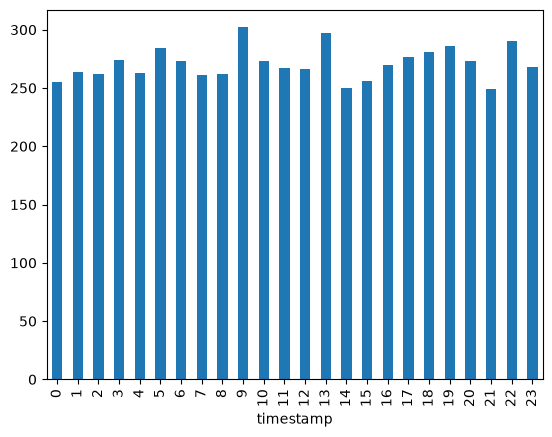

In [7]:
df.timestamp.dt.hour.value_counts().sort_index().plot(kind="bar")

There are 700 days with data out of 730 and a median of nine readings per observed day. Measurement counts are fairly balanced across hours, but the long gaps should be treated as breaks in continuity rather than ordinary missing rows.


## 3. Temperature distribution

Inspect the main operating range and determine whether high readings form isolated tails or a distinct group.


In [8]:
fig = px.histogram(
    df, x="temp_c", nbins=100,
    marginal="box",
    title="Temperature Distribution",
    labels={"temp_c": "Temperature (°C)"},
)
fig.update_layout(yaxis_title="Count")
fig.show()

### Initial distribution observations

- Most readings occupy a compact range below approximately 47°C.
- A separate group appears between approximately 170°C and 233°C, with one additional reading near 369°C.
- The separation is worth investigating, but it does not yet establish whether these readings are physical events, sensor artifacts, or another regime. No rows are removed at this stage.


## 4. Temperature over time

A timeline helps separate persistent level changes from short-lived high readings and shows where data gaps interrupt the sequence.


In [9]:
fig = px.line(df, x="timestamp", y="temp_c", title="Machine Temperature Timeline")
fig.show()


The high readings occur at multiple points across the timeline. The background temperature also changes over time, so both transient episodes and slower trends remain plausible behaviors to investigate.


## 5. Extreme-reading audit

Use the empty range between the main distribution and high-value group as an exploratory separator—not as a final alarm threshold.


In [10]:
sorted_temperatures = (
    df[["timestamp", "temp_c"]]
    .sort_values("temp_c")
    .reset_index(drop=True)
)

sorted_temperatures["previous_temp_c"] = sorted_temperatures["temp_c"].shift()
sorted_temperatures["gap_c"] = (
    sorted_temperatures["temp_c"]
    - sorted_temperatures["previous_temp_c"]
)

display (
    sorted_temperatures
    .nlargest(10, "gap_c")
    [["previous_temp_c", "temp_c", "gap_c"]]
)

# Exploratory separator only—not a model threshold.
extreme_threshold_c = 100.0

extreme_measurements = df.loc[
    df["temp_c"] > extreme_threshold_c
].copy()

extreme_summary = pd.Series(
    {
        "measurement_count": len(extreme_measurements),
        "percentage_of_data": 100 * len(extreme_measurements) / len(df),
        "affected_days": extreme_measurements["timestamp"].dt.date.nunique(),
        "minimum_temp_c": extreme_measurements["temp_c"].min(),
        "median_temp_c": extreme_measurements["temp_c"].median(),
        "maximum_temp_c": extreme_measurements["temp_c"].max(),
    }
)

display(extreme_summary)

display(
    extreme_measurements
    .assign(date=extreme_measurements["timestamp"].dt.date)
    .groupby("date")
    .agg(
        measurement_count=("temp_c", "size"),
        minimum_temp_c=("temp_c", "min"),
        maximum_temp_c=("temp_c", "max"),
    )
    .sort_values(
        ["measurement_count", "maximum_temp_c"],
        ascending=False,
    )
    .head(15)
)

,previous_temp_c,temp_c,gap_c
6502,232.778364,368.838862,136.060498
6430,47.167564,170.475797,123.308233
6495,218.181639,223.132856,4.951218
6444,184.132394,187.762699,3.630305
6499,227.294779,230.716068,3.421289
6428,43.349358,46.741306,3.391948
6497,224.272316,227.006923,2.734607
6438,177.574310,179.770588,2.196278
6437,175.379588,177.574310,2.194722
6442,182.064110,184.114997,2.050887


measurement_count      73.000000
percentage_of_data      1.122559
affected_days          50.000000
minimum_temp_c        170.475797
median_temp_c         202.822778
maximum_temp_c        368.838862
dtype: float64

,measurement_count,minimum_temp_c,maximum_temp_c
date,,,
2024-11-21,3,195.332263,368.838862
2024-12-06,2,232.167412,232.778364
2024-12-16,2,227.006923,230.716068
2024-06-05,2,210.927304,215.749886
2024-11-06,2,212.641502,215.498789
2024-02-09,2,210.041392,213.592412
2024-12-02,2,211.542696,212.092741
2024-06-04,2,210.790417,211.950436
2024-01-25,2,208.169581,211.232401


In [11]:
day = pd.Timestamp("2023-09-23").date()
df[df["timestamp"].dt.date == day].sort_values("timestamp")

,timestamp,temp_c
2463,2023-09-23 00:00:00,15.022868
2464,2023-09-23 02:00:00,206.886573
2465,2023-09-23 03:00:00,206.681769
2466,2023-09-23 04:00:00,16.703547
2467,2023-09-23 08:00:00,22.234708
2468,2023-09-23 09:00:00,21.507102
2469,2023-09-23 13:00:00,21.603989
2470,2023-09-23 17:00:00,21.533443
2471,2023-09-23 18:00:00,20.234567
2472,2023-09-23 21:00:00,18.300155


The 73 readings above 100°C represent about 1.12% of the data and occur on 50 days. Their clear separation from the main range supports analyzing them as a distinct behavior, while retaining the original values until their temporal context is understood.


###  Extreme reading rate by hour

Raw hourly counts describe coverage. Dividing extreme counts by all readings at each hour asks whether the high-value group is concentrated at particular times of day.


In [12]:
hourly_extreme_rate = (
    df.assign(
        hour=df["timestamp"].dt.hour,
        is_extreme=df["temp_c"] > extreme_threshold_c,
    )
    .groupby("hour")
    .agg(
        total_readings=("temp_c", "size"),
        extreme_readings=("is_extreme", "sum"),
    )
)

hourly_extreme_rate["extreme_rate_pct"] = (
    100
    * hourly_extreme_rate["extreme_readings"]
    / hourly_extreme_rate["total_readings"]
)

display(hourly_extreme_rate)

fig = px.bar(
    hourly_extreme_rate.reset_index(),
    x="hour",
    y="extreme_rate_pct",
    title="Extreme-Reading Rate by Hour of Day",
    labels={"hour": "Hour of day", "extreme_rate_pct": "Extreme readings (%)"},
)
fig.show()


,total_readings,extreme_readings,extreme_rate_pct
hour,,,
0,255,0,0.000000
1,264,3,1.136364
2,262,5,1.908397
3,274,7,2.554745
4,263,4,1.520913
5,284,0,0.000000
6,273,4,1.465201
7,261,3,1.149425
8,262,2,0.763359


The extreme-reading rate does not differ substantially by hour. Given the small number of extreme readings, the observed hourly differences are not strong evidence of a time-of-day pattern.


### Group extreme rows into episodes

Consecutive high readings may represent one short episode rather than independent anomalies. A four-hour boundary follows the observed short-gap sampling pattern and remains exploratory.


In [13]:
df_sorted = df.sort_values("timestamp").reset_index(drop=True).copy()
df_sorted["time_gap_hours"] = (
    df_sorted["timestamp"].diff().dt.total_seconds() / 3600
)
df_sorted["is_extreme"] = df_sorted["temp_c"] > extreme_threshold_c

previous_was_extreme = df_sorted["is_extreme"].shift(fill_value=False)
df_sorted["starts_extreme_episode"] = (
    df_sorted["is_extreme"]
    & (
        ~previous_was_extreme
        | (df_sorted["time_gap_hours"] > 4)
    )
)
df_sorted["extreme_episode_id"] = (
    df_sorted["starts_extreme_episode"].cumsum().where(df_sorted["is_extreme"])
)

extreme_episodes = (
    df_sorted.loc[df_sorted["is_extreme"]]
    .groupby("extreme_episode_id")
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        measurement_count=("temp_c", "size"),
        minimum_temp_c=("temp_c", "min"),
        maximum_temp_c=("temp_c", "max"),
    )
)

display(
    extreme_episodes["measurement_count"]
    .value_counts()
    .sort_index()
    .rename("episode_count")
)
display(extreme_episodes.head(10))


measurement_count
1    28
2    21
3     1
Name: episode_count, dtype: int64

,start_time,end_time,measurement_count,minimum_temp_c,maximum_temp_c
extreme_episode_id,,,,,
1.0,2023-03-03 08:00:00,2023-03-03 12:00:00,2,187.762699,189.007695
2.0,2023-03-15 23:00:00,2023-03-15 23:00:00,1,175.379588,175.379588
3.0,2023-03-28 07:00:00,2023-03-28 07:00:00,1,180.611409,180.611409
4.0,2023-05-05 01:00:00,2023-05-05 01:00:00,1,199.605197,199.605197
5.0,2023-05-31 19:00:00,2023-05-31 19:00:00,1,205.526147,205.526147
6.0,2023-07-01 09:00:00,2023-07-01 09:00:00,1,177.574310,177.574310
7.0,2023-07-06 20:00:00,2023-07-06 20:00:00,1,218.181639,218.181639
8.0,2023-07-20 09:00:00,2023-07-20 09:00:00,1,182.064110,182.064110
9.0,2023-07-26 03:00:00,2023-07-26 03:00:00,1,190.085819,190.085819


## 6. Short-term temperature change

Normalizing temperature differences by elapsed time is useful for identifying abrupt transitions under irregular sampling. It is a diagnostic for jumps, not yet a measure of the requested gradual trend.


In [14]:
df_sorted = df.sort_values("timestamp").copy()
df_sorted["temp_delta"] = df_sorted["temp_c"].diff()

df_sorted["time_gap_hours"] = df_sorted["timestamp"].diff().dt.total_seconds() / 3600
df_sorted["rate_c_per_hours"] = df_sorted["temp_delta"] / df_sorted["time_gap_hours"]

df_sorted["rate_c_per_hours"].describe()


count    6502.000000
mean       -0.077140
std        11.410161
min      -189.978222
25%        -0.827137
50%         0.002485
75%         0.826466
max       195.179244
Name: rate_c_per_hours, dtype: float64

In [15]:
fig = px.histogram(
    df_sorted, x="rate_c_per_hours", nbins=100,
    marginal="box",
    title="Temperature Jump Normalized on Time Gap Distribution (diff/time from last measurment)",
    labels={"rate_c_per_hours": "Temperature change rate (°C/hour)"},
)
fig.update_layout(yaxis_title="Count")
fig.show()

The distribution is centered near zero but has large positive and negative tails. These tails may reflect entry into and recovery from extreme episodes. Before interpreting them physically, compare transitions involving extreme readings with ordinary transitions and exclude long gaps where continuity is unknown.


## 7. Daily (diurnal) cycle check

Before treating any multi-day rise as a developing fault, check whether temperature simply follows a daily cycle (e.g. ambient/operational heating through the day). Extreme readings are excluded here so they don't distort the normal-range pattern.

In [16]:
normal_range = df.loc[df["temp_c"] <= extreme_threshold_c].copy()
normal_range["hour"] = normal_range["timestamp"].dt.hour

hourly_temp = normal_range.groupby("hour")["temp_c"].agg(["mean", "median", "std", "count"])
print(f'Hourly mean range: {hourly_temp["mean"].max() - hourly_temp["mean"].min():.1f}°C')

fig = px.line(
    hourly_temp.reset_index(), x="hour", y="mean",
    title="Mean Temperature by Hour of Day (extreme readings excluded)",
    labels={"hour": "Hour of day", "mean": "Mean temperature (°C)"},
)
fig.show()

Hourly mean range: 8.0°C


A clear diurnal cycle is present: mean temperature dips to about 15.8°C overnight (01:00-03:00) and peaks near 23.8°C in early afternoon (13:00), an ~8°C daily swing. This is a separate, faster-period cycle from the annual seasonal pattern modeled in section 8 below — both are real, recurring effects unrelated to the developing-fault behavior being targeted. Trend features (rolling mean/slope) should be computed over daily or longer windows, or detrended by hour, so this normal daily cycle isn't mistaken for the gradual multi-day rise the model is meant to catch.

## Interim findings and next questions

- The observed schema is simple and contains no null values; duplicate and ordering checks remain explicit.
- Sampling is sparse but reasonably distributed across hours, with two long breaks in continuity.
- High readings form a clearly separated group, but their meaning is not yet known and they are retained.
- Next, examine values immediately before and after each extreme episode, then analyze the slower background trend with robust rolling summaries.


## 8. Isolating the developing issue

The case description states the fault should appear as a *consistent, gradual increase* in temperature, which is a different signature from the isolated high-value readings audited above. This section separates the two: exclude the extreme group (`temp_c > extreme_threshold_c`) and look for a slow drift in what remains.

In [17]:
# Descriptive EDA only: use non-extreme Jan-Sep readings from both years
# to visualize the recurring annual shape. This curve is not used for
# model selection, threshold calibration, or the final detector.
seasonal_eda_subset = df[
    (df["temp_c"] <= extreme_threshold_c)
    & (df["timestamp"].dt.month <= 9)
]

day_of_year = seasonal_eda_subset["timestamp"].dt.dayofyear.to_numpy()
seasonal_design = np.column_stack(
    [
        np.ones_like(day_of_year, dtype=float),
        np.cos(2 * np.pi * day_of_year / 365),
        np.sin(2 * np.pi * day_of_year / 365),
    ]
)
seasonal_coefficients, *_ = np.linalg.lstsq(
    seasonal_design,
    seasonal_eda_subset["temp_c"].to_numpy(),
    rcond=None,
)

plot_df = df.copy()
plot_day_of_year = plot_df["timestamp"].dt.dayofyear.to_numpy()
plot_design = np.column_stack(
    [
        np.ones_like(plot_day_of_year, dtype=float),
        np.cos(2 * np.pi * plot_day_of_year / 365),
        np.sin(2 * np.pi * plot_day_of_year / 365),
    ]
)
plot_df["seasonal_expected_c"] = plot_design @ seasonal_coefficients

fig = px.line(
    plot_df,
    x="timestamp",
    y=["temp_c", "seasonal_expected_c"],
    title="Temperature vs. Descriptive Seasonal Curve",
    labels={"value": "Temperature (°C)", "variable": ""},
)
fig.show()


This curve is a descriptive EDA aid fitted to non-extreme January–September readings from both years. It suggests a recurring annual pattern, but it is not treated as a healthy baseline or used in model selection. Part 2 uses an earlier chronological training period and a separate 2023 validation period.


October–December are omitted from this descriptive curve because they contain the behavior under investigation. This is an exploratory visualization choice, not evidence that those months are confirmed faults.


In [18]:
baseline = df[df.temp_c <= extreme_threshold_c].set_index("timestamp")
monthly_median = (
    baseline["temp_c"]
    .resample("MS")
    .median()
    .rename("median_temp_c")
)
monthly_median.to_frame()

,median_temp_c
timestamp,
2023-01-01,14.895912
2023-02-01,15.157363
2023-03-01,16.786967
2023-04-01,17.988964
2023-05-01,19.646467
2023-06-01,20.701694
2023-07-01,21.095595
2023-08-01,20.307849
2023-09-01,19.542743


Both years show a similar seasonal shape from January through September. The late-year behavior is examined separately because it may combine normal seasonality with the developing issue described in the assignment.


In [19]:
weekly_2023_tail = baseline.loc["2023-10-01":"2023-12-31", "temp_c"].resample("W").median()
weekly_2024_tail = baseline.loc["2024-10-01":, "temp_c"].resample("W").median()

print("2023 Oct-Dec weekly median:")
display(weekly_2023_tail)
print("2024 Oct-end weekly median:")
display(weekly_2024_tail)

2023 Oct-Dec weekly median:


timestamp
2023-10-01    19.786642
2023-10-08    19.347160
2023-10-15    19.795112
2023-10-22    22.586122
2023-10-29    24.594934
2023-11-05    26.320837
2023-11-12    29.577165
2023-11-19    32.631935
2023-11-26          NaN
2023-12-03          NaN
2023-12-10    15.497850
2023-12-17    16.187444
2023-12-24    15.567511
2023-12-31    15.186033
Freq: W-SUN, Name: temp_c, dtype: float64

2024 Oct-end weekly median:


timestamp
2024-10-06    18.201408
2024-10-13    18.196985
2024-10-20    19.782566
2024-10-27    19.973717
2024-11-03    22.452405
2024-11-10    24.101044
2024-11-17    26.201116
2024-11-24    26.219379
2024-12-01    27.915195
2024-12-08    29.598528
2024-12-15    31.788095
2024-12-22    32.466502
2024-12-29    33.844808
2025-01-05    34.191006
Freq: W-SUN, Name: temp_c, dtype: float64

**2023:** the baseline climbs from ~20°C (Oct 1) to ~33°C (Nov 19), then the sensor stops reporting for about three weeks (the long gap already flagged in section 2), and when readings resume on 2023-12-07 the baseline is back down at ~13-15°C, consistent with a possible repair or reset during the gap.

**2024:** the same seasonal climb starts on the same schedule, but it does not reset. It keeps rising every week through the end of the dataset (34°C on the last recorded week), with no gap and no recovery. This is the pattern the assignment describes: a *consistent, gradual increase* that is still active when the data ends.

The 2023 episode is possibly a useful reference case. 

In [20]:
day = pd.Timestamp("2024-07-13").date()
df[df["timestamp"].dt.date == day].sort_values("timestamp")

,timestamp,temp_c


In [21]:
gap_starts = df[["timestamp"]].assign(gap_hours=df["timestamp"].diff().dt.total_seconds()/3600)
print("All gaps > 24h:")
display(gap_starts[gap_starts.gap_hours > 24])

print("Last 3 readings before the July 2024 gap, first 3 after:")
display(df[(df.timestamp >= "2024-07-03 12:00") & (df.timestamp <= "2024-07-14 08:00")])


All gaps > 24h:


,timestamp,gap_hours
2961,2023-12-07 02:00:00,485.0
4908,2024-07-14 02:00:00,243.0


Last 3 readings before the July 2024 gap, first 3 after:


,timestamp,temp_c
4904,2024-07-03 12:00:00,25.607010
4905,2024-07-03 16:00:00,25.302097
4906,2024-07-03 20:00:00,19.070450
4907,2024-07-03 23:00:00,17.818610
4908,2024-07-14 02:00:00,17.374189
4909,2024-07-14 03:00:00,18.368201
4910,2024-07-14 07:00:00,18.854162
4911,2024-07-14 08:00:00,22.850093


There is a second gap, in July 2024, that looks superficially similar (10 days missing) but behaves differently: temperature right before it is ~18°C flat, ordinary summer range, no ramp and it resumes at ~17-23°C, the same normal range. Unlike the Dec 2023 gap, there is no climb beforehand and no step-change after.

**Decision:** treat the July 2024 gap as an unrelated data-continuity interruption (possibly routine maintenance or a collection outage), not a fault related event, and do not fold it into the trend model. This is an assumption, not an established fact .

In [22]:
extreme_by_month = (
    df[df.temp_c > extreme_threshold_c]
    .assign(month=lambda d: d["timestamp"].dt.to_period("M"))
    .groupby("month")["temp_c"]
    .agg(count="count", mean_c="mean", max_c="max")
)
extreme_by_month.tail(6)

,count,mean_c,max_c
month,,,
2024-07,1,223.132856,223.132856
2024-08,3,196.217867,206.959077
2024-09,1,201.480196,201.480196
2024-10,4,193.531448,200.090603
2024-11,8,226.518306,368.838862
2024-12,8,220.402427,232.778364


Extreme readings occur more often during the late-2024 rise, but co-occurrence does not establish a shared cause. Rolling maxima would be dominated by these isolated values, so the final gradual-trend detector evaluates robust residual-level features instead. Extreme readings remain available as a separate diagnostic flag.


# Part 2: Feature Engineering & Model Selection


The alarm rule below is a working, interpretable definition rather than a technician-confirmed fault label. The assignment states that the target is a consistent gradual increase, so the detector separates expected daily and annual behavior from a persistent positive residual. Thresholds remain provisional until they can be validated with maintenance records or additional machines.


## Alarm definition

1. Estimate expected temperature from hour of day and day of year.
2. Calculate `observed - expected` for each measurement.
3. Smooth residuals with a causal time-based median so isolated spikes do not dominate.
4. Confirm an alarm only after the persistent residual crosses a calibrated threshold for several recent readings.


## 9. Chronological model-selection design

- **Baseline-model training:** January–June 2023.
- **Baseline-model validation:** July–September 2023.
- **Reference refit:** January–September 2023 after selecting the baseline.
- **Rule development:** October–December 2023.
- **Retrospective backtest:** all of 2024, evaluated only after freezing the rule.

The full timeline was inspected during EDA, so 2024 is a retrospective chronological backtest rather than a pristine unseen test. Keeping it out of the calculations used to select the final rule still provides a more honest separation between development and evaluation.


In [23]:
baseline_model_train = df[
    (df["timestamp"] >= "2023-01-01")
    & (df["timestamp"] < "2023-07-01")
].copy()

baseline_model_validation = df[
    (df["timestamp"] >= "2023-07-01")
    & (df["timestamp"] < "2023-10-01")
].copy()

reference = df[
    (df["timestamp"] >= "2023-01-01")
    & (df["timestamp"] < "2023-10-01")
].copy()

development = df[
    (df["timestamp"] >= "2023-10-01")
    & (df["timestamp"] < "2024-01-01")
].copy()

backtest = df[df["timestamp"] >= "2024-01-01"].copy()

pd.Series(
    {
        "baseline_train_rows": len(baseline_model_train),
        "baseline_validation_rows": len(baseline_model_validation),
        "reference_rows": len(reference),
        "development_rows": len(development),
        "backtest_rows": len(backtest),
    }
)


baseline_train_rows         1681
baseline_validation_rows     850
reference_rows              2531
development_rows             664
backtest_rows               3308
dtype: int64

In [24]:
def create_daily_time_features(frame):
    timestamps = frame["timestamp"]
    hour = timestamps.dt.hour + timestamps.dt.minute / 60

    return pd.DataFrame(
        {
            "hour_sin": np.sin(2 * np.pi * hour / 24),
            "hour_cos": np.cos(2 * np.pi * hour / 24),
        },
        index=frame.index,
    )


def create_seasonal_daily_time_features(frame):
    timestamps = frame["timestamp"]
    hour = timestamps.dt.hour + timestamps.dt.minute / 60
    day_of_year = timestamps.dt.dayofyear

    return pd.DataFrame(
        {
            "hour_sin": np.sin(2 * np.pi * hour / 24),
            "hour_cos": np.cos(2 * np.pi * hour / 24),
            "year_sin": np.sin(
                2 * np.pi * (day_of_year - 1) / 365.25
            ),
            "year_cos": np.cos(
                2 * np.pi * (day_of_year - 1) / 365.25
            ),
        },
        index=frame.index,
    )


**Huber regression** provides a smooth and interpretable expected-temperature baseline while limiting the influence of isolated extreme readings. Unlike ordinary least squares, its loss becomes approximately linear for large residuals, so a small number of extreme measurements cannot disproportionately shift the baseline. It does not eliminate the need for chronological validation: a sustained abnormal pattern inside the reference period could still influence the fit.


In [25]:
candidate_daily_model = HuberRegressor(max_iter=1000)
candidate_seasonal_daily_model = HuberRegressor(max_iter=1000)

candidate_daily_model.fit(
    create_daily_time_features(baseline_model_train),
    baseline_model_train["temp_c"],
)

candidate_seasonal_daily_model.fit(
    create_seasonal_daily_time_features(baseline_model_train),
    baseline_model_train["temp_c"],
)


,"max_iter max_iter: int, default=100Maximum number of iterations that``scipy.optimize.minimize(method=""L-BFGS-B"")`` should run for.",1000
,"epsilon epsilon: float, default=1.35The parameter epsilon controls the number of samples that should beclassified as outliers. The smaller the epsilon, the more robust it isto outliers. Epsilon must be in the range `[1, inf)`.",1.35
,"alpha alpha: float, default=0.0001Strength of the squared L2 regularization. Note that the penalty isequal to ``alpha * ||w||^2``.Must be in the range `[0, inf)`.",0.0001
,"warm_start warm_start: bool, default=FalseThis is useful if the stored attributes of a previously used modelhas to be reused. If set to False, then the coefficients willbe rewritten for every call to fit.See :term:`the Glossary <warm_start>`.",False
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit the intercept. This can be set to Falseif the data is already centered around the origin.",True
,"tol tol: float, default=1e-05The iteration will stop when``max{|proj g_i | i = 1, ..., n}`` <= ``tol``where pg_i is the i-th component of the projected gradient.",1e-05
Name,Type,Value
"coef_ coef_: array, shape (n_features,)Features got by optimizing the L2-regularized Huber loss.","ndarray[float64](4,)","[-0.97,-3.84,-0.9 ,-2.84]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['hour_sin','hour_cos','year_sin','year_cos']"
intercept_ intercept_: floatBias.,float64,18.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4


In [26]:
def score_temperature_model(frame, model, feature_function):
    scored = frame.sort_values("timestamp").copy()
    scored["expected_temp_c"] = model.predict(
        feature_function(scored)
    )
    scored["temp_residual_c"] = (
        scored["temp_c"] - scored["expected_temp_c"]
    )
    return scored


def daily_median_residual(scored):
    return (
        scored
        .set_index("timestamp")["temp_residual_c"]
        .resample("D")
        .median()
        .rename("median_residual_c")
        .reset_index()
    )


validation_scored_daily = score_temperature_model(
    baseline_model_validation,
    candidate_daily_model,
    create_daily_time_features,
)

validation_scored_seasonal = score_temperature_model(
    baseline_model_validation,
    candidate_seasonal_daily_model,
    create_seasonal_daily_time_features,
)

validation_daily_residual = daily_median_residual(
    validation_scored_daily
).rename(
    columns={"median_residual_c": "daily_only_residual_c"}
)

validation_seasonal_residual = daily_median_residual(
    validation_scored_seasonal
).rename(
    columns={"median_residual_c": "seasonal_daily_residual_c"}
)

baseline_comparison = validation_daily_residual.merge(
    validation_seasonal_residual,
    on="timestamp",
    how="inner",
).dropna()

residual_columns = [
    "daily_only_residual_c",
    "seasonal_daily_residual_c",
]

baseline_comparison_summary = pd.DataFrame(
    {
        "median_residual_c": baseline_comparison[
            residual_columns
        ].median(),
        "median_absolute_residual_c": baseline_comparison[
            residual_columns
        ].abs().median(),
        "residual_mad_c": baseline_comparison[
            residual_columns
        ].apply(
            lambda values: (
                values - values.median()
            ).abs().median()
        ),
    },
    index=residual_columns,
)

baseline_comparison_summary.index = [
    "daily_only",
    "seasonal_and_daily",
]

baseline_comparison_summary


,median_residual_c,median_absolute_residual_c,residual_mad_c
daily_only,3.375366,3.375366,0.542153
seasonal_and_daily,0.154658,0.366583,0.329123


In [27]:
fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    subplot_titles=[
        "Daily + Seasonal Baseline",
        "Daily-Only Baseline",
    ],
)

fig.add_trace(
    go.Scatter(
        x=baseline_comparison["timestamp"],
        y=baseline_comparison["seasonal_daily_residual_c"],
        name="Daily + seasonal",
    ),
    row=1,
    col=1,
)

fig.add_trace(
    go.Scatter(
        x=baseline_comparison["timestamp"],
        y=baseline_comparison["daily_only_residual_c"],
        name="Daily only",
    ),
    row=2,
    col=1,
)

fig.add_hline(y=0, line_dash="dash", row=1, col=1)
fig.add_hline(y=0, line_dash="dash", row=2, col=1)
fig.update_yaxes(title_text="Residual (°C)", row=1, col=1)
fig.update_yaxes(title_text="Residual (°C)", row=2, col=1)
fig.update_xaxes(title_text="Date", row=2, col=1)
fig.update_layout(height=650, showlegend=False)
fig.show()


### Baseline-model decision

On the July–September 2023 validation period, the daily-only model retains a large seasonal bias, while the daily-and-seasonal model remains centered near zero with substantially lower absolute residuals. The daily-and-seasonal Huber model is therefore selected and refitted on the complete January–September 2023 reference period.


In [28]:
expected_temperature_model = HuberRegressor(max_iter=1000)
expected_temperature_model.fit(
    create_seasonal_daily_time_features(reference),
    reference["temp_c"],
)

scored_df = score_temperature_model(
    df,
    expected_temperature_model,
    create_seasonal_daily_time_features,
)


## 10. Persistent residual features

The baseline residual describes how much hotter a reading is than expected for its hour and season. Causal rolling medians use only the current and preceding measurements. The 72-hour observation count makes the minimum-history requirement explicit after long gaps.


In [29]:
scored_df = scored_df.set_index("timestamp").copy()

scored_df["residual_median_24h"] = (
    scored_df["temp_residual_c"]
    .rolling("24h", min_periods=3)
    .median()
)

scored_df["residual_median_72h"] = (
    scored_df["temp_residual_c"]
    .rolling("72h", min_periods=6)
    .median()
)

scored_df["observations_72h"] = (
    scored_df["temp_residual_c"]
    .rolling("72h")
    .count()
)

scored_df["has_sufficient_history"] = (
    scored_df["observations_72h"] >= 6
)
scored_df["is_extreme_reading"] = (
    scored_df["temp_c"] > extreme_threshold_c
)

scored_df = scored_df.reset_index()


In [30]:
development_view = scored_df[
    scored_df["timestamp"] < "2024-01-01"
]

fig = px.line(
    development_view,
    x="timestamp",
    y=["residual_median_24h", "residual_median_72h"],
    title="Rolling Median Residuals During 2023 Development",
    labels={
        "timestamp": "Date",
        "value": "Observed − expected temperature (°C)",
        "variable": "Rolling feature",
    },
)
fig.add_hline(y=0, line_dash="dash")
fig.show()


### Rolling-window decision

The 24-hour median remains responsive to short clusters, while the 72-hour median suppresses them and preserves the sustained October–November 2023 increase. The 72-hour median is retained as the primary alarm signal, accepting a modest detection delay in exchange for greater robustness to isolated spikes.


In [31]:
reference_mask = (
    (scored_df["timestamp"] >= reference["timestamp"].min())
    & (scored_df["timestamp"] <= reference["timestamp"].max())
)
development_mask = (
    (scored_df["timestamp"] >= development["timestamp"].min())
    & (scored_df["timestamp"] <= development["timestamp"].max())
)

reference_rolling_residual = scored_df.loc[
    reference_mask,
    "residual_median_72h",
].dropna()

reference_threshold_summary = pd.Series(
    {
        "median": reference_rolling_residual.median(),
        "95th_percentile": reference_rolling_residual.quantile(0.95),
        "99th_percentile": reference_rolling_residual.quantile(0.99),
        "99.5th_percentile": reference_rolling_residual.quantile(0.995),
        "maximum": reference_rolling_residual.max(),
    }
)

reference_threshold_summary


median               0.003685
95th_percentile      0.443772
99th_percentile      0.638275
99.5th_percentile    0.670615
maximum              0.765912
dtype: float64

In [32]:
def count_alarm_episodes(alarm, period_mask):
    period_alarm = alarm.loc[period_mask]
    return int(
        (
            period_alarm
            & ~period_alarm.shift(fill_value=False)
        ).sum()
    )


candidate_thresholds = {
    "reference_99_5_percentile": (
        reference_rolling_residual.quantile(0.995)
    ),
    "reference_maximum": reference_rolling_residual.max(),
    "rounded_1_degree": 1.0,
}

threshold_results = []

for threshold_name, threshold_c in candidate_thresholds.items():
    candidate = (
        scored_df["residual_median_72h"] > threshold_c
    ).fillna(False)

    threshold_results.append(
        {
            "threshold": threshold_name,
            "threshold_c": threshold_c,
            "reference_alarm_rate": candidate[reference_mask].mean(),
            "reference_episodes": count_alarm_episodes(
                candidate,
                reference_mask,
            ),
            "first_development_alarm": scored_df.loc[
                candidate & development_mask,
                "timestamp",
            ].min(),
        }
    )

threshold_comparison = pd.DataFrame(threshold_results)
threshold_comparison


,threshold,threshold_c,reference_alarm_rate,reference_episodes,first_development_alarm
0,reference_99_5_percentile,0.670615,0.004346,4,2023-10-12 19:00:00
1,reference_maximum,0.765912,0.000000,0,2023-10-12 19:00:00
2,rounded_1_degree,1.000000,0.000000,0,2023-10-12 22:00:00


### Threshold decision

The `1°C` threshold produces no reference-period alarms and detects the 2023 development episode only a few hours after the more sensitive thresholds. It is retained as a conservative, interpretable working threshold rather than an optimized physical limit.


## 11. Alternative trend feature: seven-day slope

A positive slope directly represents gradual increase, so it is evaluated as a possible early-warning feature. Daily residual medians reduce the influence of irregular sampling and extreme readings; shifting the result by one day ensures that each value uses only completed previous days.


In [33]:
daily_feature_df = (
    scored_df
    .set_index("timestamp")["temp_residual_c"]
    .resample("D")
    .median()
    .rename("daily_median_residual_c")
    .to_frame()
)


def calculate_rolling_slope(values):
    valid_values = ~np.isnan(values)

    if valid_values.sum() < 5:
        return np.nan

    days = np.arange(len(values))[valid_values]
    residuals = values[valid_values]
    return np.polyfit(days, residuals, 1)[0]


slope_column = "causal_residual_slope_7d_c_per_day"
daily_feature_df[slope_column] = (
    daily_feature_df["daily_median_residual_c"]
    .rolling(window=7, min_periods=5)
    .apply(calculate_rolling_slope, raw=True)
    .shift(1)
)

reference_slope = daily_feature_df.loc[
    "2023-01-01":"2023-09-30",
    slope_column,
].dropna()

scored_df[slope_column] = (
    scored_df["timestamp"]
    .dt.normalize()
    .map(daily_feature_df[slope_column])
)


In [34]:
fig = px.line(
    daily_feature_df.loc[:"2023-12-31"].reset_index(),
    x="timestamp",
    y=slope_column,
    title="Seven-Day Causal Residual Slope During Development",
    labels={
        "timestamp": "Date",
        slope_column: "Residual slope (°C/day)",
    },
)
fig.add_hline(y=0, line_dash="dash")
fig.show()

pd.Series(
    {
        "median": reference_slope.median(),
        "95th_percentile": reference_slope.quantile(0.95),
        "99th_percentile": reference_slope.quantile(0.99),
        "maximum": reference_slope.max(),
    }
)


median            -0.002726
95th_percentile    0.160862
99th_percentile    0.231791
maximum            0.271548
dtype: float64

In [35]:
sensitive_level_threshold = reference_rolling_residual.quantile(0.995)
conservative_level_threshold = 1.0
slope_95_threshold = reference_slope.quantile(0.95)
slope_99_threshold = reference_slope.quantile(0.99)

level_signal = scored_df["residual_median_72h"]
slope_signal = scored_df[slope_column]

candidate_rules = {
    "level_only_1_degree": (
        level_signal > conservative_level_threshold
    ),
    "hybrid_slope_95": (
        (level_signal > conservative_level_threshold)
        | (
            (level_signal > sensitive_level_threshold)
            & (slope_signal > slope_95_threshold)
        )
    ),
    "hybrid_slope_99": (
        (level_signal > conservative_level_threshold)
        | (
            (level_signal > sensitive_level_threshold)
            & (slope_signal > slope_99_threshold)
        )
    ),
}

rule_results = []

for rule_name, candidate in candidate_rules.items():
    candidate = candidate.fillna(False)
    rule_results.append(
        {
            "rule": rule_name,
            "reference_alarm_rate": candidate[reference_mask].mean(),
            "reference_episodes": count_alarm_episodes(
                candidate,
                reference_mask,
            ),
            "first_development_alarm": scored_df.loc[
                candidate & development_mask,
                "timestamp",
            ].min(),
        }
    )

rule_comparison = pd.DataFrame(rule_results)
rule_comparison


,rule,reference_alarm_rate,reference_episodes,first_development_alarm
0,level_only_1_degree,0.000000,0,2023-10-12 22:00:00
1,hybrid_slope_95,0.002766,1,2023-10-12 22:00:00
2,hybrid_slope_99,0.002766,1,2023-10-12 22:00:00


### Slope feature decision

The seven-day slope rises during the suspected 2023 event, but the hybrid rules do not detect that event earlier than the level-only rule and introduce a reference-period nuisance episode. The slope is therefore rejected from the final detector: it adds parameters and operational complexity without meaningful development-period benefit.


## 12. Final provisional alarm rule

A measurement becomes an alarm when the 72-hour median residual exceeds `1°C` for three consecutive readings occurring within 24 hours. The confirmation step removes brief threshold crossings while remaining causal. It is a working statistical rule, not a technician-approved physical limit.


In [36]:
final_threshold_c = 1.0

scored_df["candidate_alarm"] = (
    scored_df["has_sufficient_history"]
    & (scored_df["residual_median_72h"] > final_threshold_c)
)

three_consecutive_candidates = (
    scored_df["candidate_alarm"]
    .astype(int)
    .rolling(window=3, min_periods=3)
    .sum()
    .eq(3)
)

three_reading_span = (
    scored_df["timestamp"]
    - scored_df["timestamp"].shift(2)
)

scored_df["alarm"] = (
    three_consecutive_candidates
    & (three_reading_span <= pd.Timedelta("24h"))
)


In [37]:
alarm_start = (
    scored_df["alarm"]
    & ~scored_df["alarm"].shift(fill_value=False)
)

scored_df["alarm_episode_id"] = (
    alarm_start.cumsum().where(scored_df["alarm"])
)

alarm_episode_summary = (
    scored_df[scored_df["alarm"]]
    .groupby("alarm_episode_id")
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        measurement_count=("timestamp", "size"),
        maximum_rolling_residual_c=(
            "residual_median_72h",
            "max",
        ),
    )
    .reset_index()
)

alarm_episode_summary["duration_hours"] = (
    alarm_episode_summary["end"]
    - alarm_episode_summary["start"]
).dt.total_seconds() / 3600

alarm_episode_summary


,alarm_episode_id,start,end,measurement_count,maximum_rolling_residual_c,duration_hours
0,1.0,2023-10-13 12:00:00,2023-11-16 21:00:00,315,14.273494,825.0
1,2.0,2024-10-17 17:00:00,2024-12-30 23:00:00,695,19.698932,1782.0


## 13. Retrospective chronological backtest

The rule is now frozen before evaluating 2024. Because the full timeline was visible during EDA, this is described as a retrospective chronological backtest rather than an untouched test set. It still checks whether the 2023-developed rule remains quiet during January–September 2024 and responds to the later sustained rise.


In [38]:
backtest_normal_mask = (
    (scored_df["timestamp"] >= "2024-01-01")
    & (scored_df["timestamp"] < "2024-10-01")
)
backtest_late_year_mask = scored_df["timestamp"] >= "2024-10-01"

backtest_summary = pd.Series(
    {
        "jan_sep_alarm_rate": scored_df.loc[
            backtest_normal_mask,
            "alarm",
        ].mean(),
        "jan_sep_alarm_episodes": count_alarm_episodes(
            scored_df["alarm"],
            backtest_normal_mask,
        ),
        "first_late_year_alarm": scored_df.loc[
            backtest_late_year_mask & scored_df["alarm"],
            "timestamp",
        ].min(),
    }
)

backtest_normal_df = scored_df.loc[backtest_normal_mask].copy()
hourly_residual_bias = (
    backtest_normal_df
    .groupby(backtest_normal_df["timestamp"].dt.hour)[
        "temp_residual_c"
    ]
    .median()
)
monthly_residual_bias = (
    backtest_normal_df
    .groupby(backtest_normal_df["timestamp"].dt.to_period("M"))[
        "temp_residual_c"
    ]
    .median()
)

display(backtest_summary)
display(hourly_residual_bias.rename("median_residual_c"))
display(monthly_residual_bias.rename("median_residual_c"))


jan_sep_alarm_rate                        0.0
jan_sep_alarm_episodes                      0
first_late_year_alarm     2024-10-17 17:00:00
dtype: object

timestamp
0    -0.133194
1    -0.291539
2    -0.440307
3     0.138204
4    -0.328584
5     0.001315
6     0.273143
7    -0.163505
8    -0.304763
9     0.064894
10   -0.265047
11    0.163918
12    0.345001
13    0.072805
14    0.165149
15    0.142675
16   -0.063450
17    0.056625
18   -0.201663
19   -0.015025
20   -0.146788
21   -0.038210
22    0.220188
23   -0.066418
Name: median_residual_c, dtype: float64

timestamp
2024-01    0.060327
2024-02   -0.074463
2024-03   -0.038210
2024-04    0.109818
2024-05    0.007103
2024-06    0.096076
2024-07   -0.155232
2024-08   -0.203617
2024-09   -0.311544
Freq: M, Name: median_residual_c, dtype: float64

In [39]:
normal_context_mask = reference_mask | backtest_normal_mask

spike_robustness_summary = pd.Series(
    {
        "extreme_readings_in_normal_context": scored_df.loc[
            normal_context_mask,
            "is_extreme_reading",
        ].sum(),
        "extreme_readings_labeled_alarm": (
            scored_df["is_extreme_reading"]
            & scored_df["alarm"]
            & normal_context_mask
        ).sum(),
        "alarm_episodes_in_normal_context": count_alarm_episodes(
            scored_df["alarm"],
            normal_context_mask,
        ),
    }
)

spike_robustness_summary


extreme_readings_in_normal_context    46
extreme_readings_labeled_alarm         0
alarm_episodes_in_normal_context       0
dtype: int64

In [40]:
daily_temperature_plot = (
    scored_df
    .set_index("timestamp")[["temp_c", "expected_temp_c"]]
    .resample("D")
    .median()
    .reset_index()
)

alarm_rows = scored_df[scored_df["alarm"]]

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.08,
    subplot_titles=[
        "Observed and Expected Daily Median Temperature",
        "Alarm Signal and Predictions",
    ],
)

fig.add_trace(
    go.Scatter(
        x=daily_temperature_plot["timestamp"],
        y=daily_temperature_plot["temp_c"],
        name="Observed temperature",
        line={"color": "royalblue"},
    ),
    row=1,
    col=1,
)

fig.add_trace(
    go.Scatter(
        x=daily_temperature_plot["timestamp"],
        y=daily_temperature_plot["expected_temp_c"],
        name="Expected temperature",
        line={"color": "gray", "dash": "dash"},
    ),
    row=1,
    col=1,
)

fig.add_trace(
    go.Scatter(
        x=scored_df["timestamp"],
        y=scored_df["residual_median_72h"],
        name="72-hour median residual",
        line={"color": "royalblue"},
    ),
    row=2,
    col=1,
)

fig.add_trace(
    go.Scatter(
        x=alarm_rows["timestamp"],
        y=alarm_rows["residual_median_72h"],
        name="Alarm",
        mode="markers",
        marker={"color": "red", "size": 5},
    ),
    row=2,
    col=1,
)

fig.add_hline(
    y=final_threshold_c,
    line_dash="dash",
    line_color="orange",
    annotation_text="Provisional alarm threshold: 1°C",
    row=2,
    col=1,
)

for _, episode in alarm_episode_summary.iterrows():
    episode_end = max(
        episode["end"],
        episode["start"] + pd.Timedelta(hours=1),
    )

    for row_number in (1, 2):
        fig.add_vrect(
            x0=episode["start"],
            x1=episode_end,
            fillcolor="red",
            opacity=0.10,
            line_width=0,
            row=row_number,
            col=1,
        )

fig.update_yaxes(title_text="Temperature (°C)", row=1, col=1)
fig.update_yaxes(title_text="Residual (°C)", row=2, col=1)
fig.update_xaxes(title_text="Date", row=2, col=1)
fig.update_layout(
    title="Temperature Anomaly Alarm Predictions",
    height=750,
    hovermode="x unified",
)
fig.show()


## Final interpretation and limitations

The provisional detector identifies the sustained late-2023 and late-2024 increases while remaining quiet during the reference period and the January–September 2024 backtest period. Isolated extreme readings in those normal-context periods do not become alarms.

This does not establish ground truth. The dataset contains one unlabeled machine, the suspected events were identified during EDA, and there is no confirmed healthy late-year comparison period. The low-capacity baseline, chronological separation, robust rolling feature, rejected-feature analysis, and explicit backtest reduce overfitting risk, but the threshold and confirmation settings should be validated on additional machines or maintenance records before operational use.
